---
title: "Ethylene oxide in a wall-cooled tube: can the kinetics' own window run away? (Borman and Westerterp, 1995)"
description: "Model III kinetics of ethene oxidation over silver in a 1-D wall-cooled tube, tested for parametric sensitivity by Morbidelli and Varma's generalized criterion: with Table 6 as printed the window holds no sensitive point, with the combustion factor of C2.11 the runaway boundary lies inside it."
categories: [sec:D, struct:S2, tier:T1, data:tier2, phase:gas-solid]
date: 2026-11-27
---

# Ethylene oxide multitubular: is the kinetic window parametrically sensitive?

**Catalog ID:** `D3.5` · **Structures:** `S2` (plug flow with reaction and wall cooling) ·
**Tier:** T1

Borman and Westerterp measured the kinetics of ethene epoxidation and combustion over a
silver catalyst because they wanted a strongly exothermic reaction for their work on
wall-cooled packed beds, and they ran it in air below the lower explosion limit of ethene.
**The paper prints no tube**: no diameter, length, coolant, flow or wall coefficient, and
no reactor measurement. This page therefore puts their model III kinetics (as rebuilt on
page `C2.11`) into a 1-D wall-cooled plug-flow tube whose geometry, wall coefficient and
heat capacity are borrowed from page `C2.10` and named as page choices, and asks one
question: inside the paper's own operating window, does such a tube become parametrically
sensitive by Morbidelli and Varma's generalized criterion? The answer depends on the
combustion rate constant: Table 6 as printed (factor `F = 1`) against the factor `F_fig6`
that reproduces the authors' own Figure 6 (`C2.11`). Nothing on this page is compared with
reactor or plant data; none is printed.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.4"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "D3.5-ethylene-oxide-multitubular-runaway"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import math
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from scipy.integrate import quad
from pymrm.checks import find_roots, observed_orders

from gallery_utils import (Claims, assert_check_values, cite_data, load_claims, load_data,
                           load_meta)
from model import (R_GAS, CooledTube, Kinetics, critical_point, inlet, rate, richardson,
                   scan_sensitivity, refine_extremum, table6_model3)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
warnings.filterwarnings("ignore", message="overflow encountered")   # trial states of newton


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))


def show(frame, uuid, fmt=None):
    """Display a table with a pinned id, so two runs print the same HTML."""
    sty = frame.style.hide(axis="index")
    if fmt:
        sty = sty.format(fmt)
    display(HTML(sty.set_uuid(uuid).to_html()))

## Background

Ethene oxide is made in multitubular reactors: thousands of tubes packed with a silver
catalyst, cooled from outside. Two parallel reactions compete, the epoxidation and the
total combustion, and the combustion releases an order of magnitude more heat per ethene. A tube of this kind is the textbook case of parametric sensitivity: below a
critical cooling the hot spot does not grow gradually, it jumps.

Borman and Westerterp (1995) measured the kinetics in a gradientless recycle reactor on a
catalyst batch that had first been exposed for a long time in their wall-cooled packed
bed, so that the two studies would be compatible. They state their purpose (S1 to S7
below are their words, from the page images): the reactions "are strongly exothermic, and
we desire to use them for investigating heat effects in packed bed reactors" (S1), run in
air "under the lower explosion limit" (S2). The paper itself reports no tube.

Page `C2.11` rebuilt the kinetics and found that the combustion rate constant of model III
as printed in Table 6 is about two decades too small to reproduce the authors' own
Figure 6; one factor `F_fig6` restores the figure. A sensitivity question is where that
difference matters most, because the combustion carries the heat. This page asks it with
the paper's own window and a borrowed tube.

**What is not repeated here:** the selectivity derivatives, the factor fit and the Table 4
inversion (`C2.11`); 1-D against 2-D models and the o-xylene case (`C2.10`); the
Van Welsenaere-Froment criteria (`D2.2`: they need one reaction in a phase plane, here
there are two with product inhibition, which is why the generalized criterion is used);
Barkelew's criterion (`D2.1`); film and particle gradients (`D1.1`). Not covered: ethene
oxide oxidation (neglected, as the paper does), pressure drop, radial gradients, interphase
gradients, the oxygen process, and flammability.

## The published model

**Reactions and heats** (p. 49): epoxidation
$\mathrm{C_2H_4 + \tfrac12 O_2 \to C_2H_4O}$, $\Delta H_1$; combustion
$\mathrm{C_2H_4 + 3\,O_2 \to 2\,CO_2 + 2\,H_2O}$, $\Delta H_2$ (per mol ethene); the
printed values are in the table of printed numbers below.

**Rates** (Table 5, model III, the Table 6 caption form, as on `C2.11`):
$$r_i = \frac{k_{r,i}\,K_{E,i}\,K_{O,i}^{1/2}\,P_E\,P_O^{1/2}}
{\bigl(1 + K_{E,i}P_E + (K_{O,i}P_O)^{1/2} + K_{C,i}P_C + K_{EO,i}P_{EO} + K_{W,i}P_W\bigr)^2},
\qquad k_{r,i} = k_{\infty,i}\,e^{-T_{act,i}/T},$$
with $K_j = K_{j,\infty} e^{T_{ads,j}/T}$ where Table 6 prints a pair, the 476 K value
otherwise. $r_1$ is the ethene oxide production rate, $r_2$ the **CO2 production rate**
(eq. 2): the combustion burns $r_2/2$ ethene. The factor $F$ multiplies $r_2$.

**The tube (page model, E3).** Steady, isobaric, 1-D pseudo-homogeneous plug flow in the
space time $w = W/\dot m$ (kg cat s per kg gas), amounts $n_j$ per kg of gas:
$$\frac{dn_E}{dw} = -a\bigl(r_1 + \tfrac12 r_2\bigr),\quad
\frac{dn_O}{dw} = -a\bigl(\tfrac12 r_1 + \tfrac32 r_2\bigr),\quad
\frac{dn_C}{dw} = \frac{dn_W}{dw} = a\,r_2,\quad \frac{dn_{EO}}{dw} = a\,r_1,$$
$$c_p\frac{dT}{dw} = a\,q - h\,(T - T_c),\qquad q = (-\Delta H_1)\,r_1 + (-\Delta H_2)\,\tfrac12 r_2,
\qquad h = \frac{4U}{d_t\,\rho_b},$$
with $T(0) = T_c$ and the inlet ethene fraction $y_E$ in dry air. $P_j = P\,n_j/\sum_k n_k$
(nitrogen included). Replacing $w$ by $a\,w$ maps $(a, h)$ onto $(1, h/a)$ exactly (E15), so
the cooling axis of every map is $h/a$.

**Criterion** (Morbidelli and Varma 1988, eq. 34b): the normalised sensitivity of the hot
spot $T^*$ to a parameter $\phi$,
$$S^*_\phi = \frac{\phi}{T^*}\frac{dT^*}{d\phi},$$
with $T^*$ absolute (their $T$ is $T/T_a$, eq. 4); the critical $\phi$ maximises
$|S^*_\phi|$. They call the criterion intrinsic: for different $\phi$ it should give the
same critical point, which the page measures. Two references: the frozen-composition
(Semenov) tangency $h_{Sem}$, where $q(T)$ at the inlet composition touches
$h(T - T_c)$, and its Frank-Kamenetskii form $h_{FK} = e\,dq/dT|_{T_c}$.

| symbol | meaning | code |
|---|---|---|
| $n_j$, $T$ | amounts (mol/kg gas) of E, O, C, EO, W, N; temperature (K) | `u[:, 0:6]`, `u[:, 6]` |
| $w$ | space time (kg cat s/kg gas) | `CooledTube.w_f` |
| $r_1, r_2$ | epoxidation, CO2 production (mol/(kg cat s)) | `Kinetics.rates` |
| $q$, $h$, $c_p$ | heat release (W/kg cat), cooling (W/(kg cat K)), heat capacity (J/(kg K)) | `Kinetics.heat`, `h`, `c_p` |
| $F$, $a$ | factor on $r_2$; activity | `Kinetics(F=, a=)` |
| $S^*_\phi$ | MV normalised sensitivity | `CooledTube.mv` |

## Parameters and assumptions

Loaded, never retyped: Table 6 (model III) and the factors `F_fig6` and `F_row1` from
`C2.11`; the wall coefficient $U$, the tube diameter $d_t$ and the heat capacity $c_p$
from `C2.10`'s data. Printed here: heats, ring dimensions, the kinetic batch, the
explosion limit, the temperatures and pressures (file `borman-1995-reactor-numbers.csv`).

Page choices, each a decision that can be reversed by one parameter:

- **A1** dry, CO2-free air feed (as `C2.11`); **A3** activity $a = 1$: the tube catalyst
  is the kinetic lot, pre-exposed in the wall-cooled reactor (S4); **A5** heats constant;
- **A4, A8** the tube of `C2.10` (Froment's o-xylene tube): $U$, $d_t$ and $c_p$. It is a
  borrowed geometry, never "the Twente reactor"; $U$ is a typical magnitude only, which is
  why the maps run over $h/a$;
- **A7** a hull voidage $\varepsilon$ for the rings, which enters only $\rho_b$ and so
  only the $d_t$ axis; the thermochemical calorie;
- **criterion**: MV eq. 34b with absolute $T^*$ (alternative: the rise $T^* - T_c$ as
  normaliser, measured below);
- the base tube **B** is the Table 4 standard condition used as tube inlet (500 K, 0.5 MPa,
  1.8 % ethene); **M** is B at the explosion limit with `F_fig6`; **S** is B at 476 K.

In [3]:
C211 = "C2.11-borman-westerterp-eo-selectivity"
C210 = "C2.10-o-xylene-phthalic-anhydride"
T6 = load_data("borman-1995-table6.csv", page=C211, dtype=str)
PAR = table6_model3(T6)
C211_CLAIMS = load_claims(C211)
F6, F_ROW1 = C211_CLAIMS["F_fig6"], C211_CLAIMS["F_row1"]
F3_R2 = float(T6[(T6.model == "III") & (T6.reaction == "r2") & (T6.parameter == "f3")]
              .value.iloc[0])
C210_RES = load_data("froment-1967-stated-results.csv", page=C210, dtype=str)
C210_PAR = load_data("froment-1967-parameters.csv", page=C210, dtype=str)
U_KCAL = float(C210_RES.set_index("quantity").loc["U_ref", "value"])     # kcal/(m2 h K)
D_T = float(C210_PAR.set_index("symbol").loc["d_t", "value"])            # m
CP_KCAL = float(C210_PAR.set_index("symbol").loc["c_p", "value"])        # kcal/(kg K)

PN = load_data("borman-1995-reactor-numbers.csv", page=PAGE, dtype=str).set_index("quantity")
ST = load_data("borman-1995-reactor-statements.csv", page=PAGE, dtype=str)
T3 = load_data("borman-1995-table3.csv", page=C211, dtype=str)            # Table 3 (p. 51)


def pn(q):
    """A printed number as float."""
    return float(PN.loc[q, "value"])


CAL = 4184.0                        # J/kcal, thermochemical calorie (page choice)
EPS_HULL = 0.45                     # hull voidage of the ring bed (page choice A7)
DH = (-pn("dH_epoxidation") * 1e3, -pn("dH_combustion") * 1e3)    # J/mol ethene
P_TOT = pn("standard_pressure") * 10.0                             # bar
T_STD, Y_STD = pn("standard_temperature"), pn("standard_ethene") / 100.0
Y_LEL = pn("lower_explosion_limit") / 100.0
T_KIN = [pn(f"T_kinetic_{i}") for i in range(1, 5)]                # K
T_HI = max(T_KIN)


def geometry(n_part=None, hull_for_ring=False, u_unit=CAL / 3600.0, cp_unit=CAL,
             o2_per_burnt=3.0):
    """R1: ring, bed and cooling numbers from the printed dimensions and C2.10's U, d_t,
    c_p. The keyword arguments are the break-table readings."""
    od, idd, hgt = pn("ring_outer_diameter"), pn("ring_inner_diameter"), pn("ring_height")
    dod, did, dh = (pn("ring_outer_diameter_tol"), pn("ring_inner_diameter_tol"),
                    pn("ring_height_tol"))
    n_part = pn("kinetic_batch_particles") if n_part is None else n_part
    ring = lambda o, i, z: math.pi / 4 * (o ** 2 - (0.0 if hull_for_ring else i ** 2)) * z
    v_ring = ring(od, idd, hgt)                                     # mm3
    v_hull = math.pi / 4 * od ** 2 * hgt
    m_p = pn("kinetic_batch_mass") / n_part                         # g
    rho = lambda v: m_p / v * 1e6                                   # kg/m3 from g/mm3
    rho_hull = rho(v_hull)
    rho_b = (1.0 - EPS_HULL) * rho_hull
    U = U_KCAL * u_unit
    cp = CP_KCAL * cp_unit
    out = {"V_ring_mm3": v_ring, "m_particle_g": m_p, "rho_p_kgm3": rho(v_ring),
           "rho_p_min_kgm3": rho(ring(od + dod, idd - did, hgt + dh)),
           "rho_p_max_kgm3": rho(ring(od - dod, idd + did, hgt - dh)),
           "rho_hull_kgm3": rho_hull, "rho_b_kgm3": rho_b, "U_C210_SI": U, "cp_C210_SI": cp,
           "h_C210_W_per_kgK": 4.0 * U / (D_T * rho_b)}
    n0 = inlet(Y_LEL)                                               # O2 after full combustion
    out["PO_min_LEL_bar"] = P_TOT * (n0[1] - o2_per_burnt * n0[0]) / n0.sum()
    for y, tag in ((Y_STD, "018"), (Y_LEL, "03")):
        out["dTad_epox_" + tag] = inlet(y)[0] * DH[0] / cp
        out["dTad_comb_" + tag] = inlet(y)[0] * DH[1] / cp
    return out


GEO = geometry()
H_C210, CP = GEO["h_C210_W_per_kgK"], GEO["cp_C210_SI"]
print(f"F_fig6 {F6:.6g}, F_row1 {F_ROW1:.6g} (C2.11 claims); U {GEO['U_C210_SI']:.6g} W/(m2 K), "
      f"d_t {D_T:g} m, c_p {CP:.6g} J/(kg K) (C2.10 data); h_C210 {H_C210:.6g} W/(kg K)")

F_fig6 112.778, F_row1 61.9932 (C2.11 claims); U 96.1158 W/(m2 K), d_t 0.025 m, c_p 1046 J/(kg K) (C2.10 data); h_C210 19.5637 W/(kg K)


## The data

- **Printed numbers** (`borman-1995-reactor-numbers.csv`): heats, rings, batch, explosion
  limit, temperatures and pressures of the kinetic work, the Table 4 standard condition
  and the activity remark, each with its journal and PDF page and the printed words.
- **Statements S1 to S7** (`borman-1995-reactor-statements.csv`), short quotes on what
  the reaction was for, the explosion limit, the pre-exposure, extrapolation and activity.
- **Borrowed from `C2.11`**: Table 6 and its check values, the factors `F_fig6` (the
  one figure-derived input: from `C2.11`'s digitised Figure 6) and `F_row1` (Table 4 row
  1). `C2.11`'s findings about these rows: **M1**, the model III $r_2$ rate constant is
  about two decades too small in both printed forms (this page's reason for running both
  `F = 1` and `F_fig6`; the page tests the consequence, not the cause); **M3**, the
  activation energies quoted in the abstract do not round from $R\,T_{lump}$ (does not affect this page, which uses the caption form); **M4**, models
  II and III print identical $r_1$ adsorption constants (the Figure 6 fit shows these are
  what the authors used; used as printed).
- **Borrowed from `C2.10`**: $U$ (stated-results row `U_ref`), $d_t$ and $c_p$.
  `C2.10`'s findings: two printed values there carry a European thousands separator
  ($G$ and $\Delta H_3$; neither is used here); $U$ is a reconstructed 1-D coefficient
  built from $\lambda_R$ and $\alpha_w$ (p. 26), not a measurement. Neither affects this
  page beyond what A8 says.

No number comes from a figure of this paper.

In [4]:
show(PN.reset_index()[["quantity", "value", "unit", "journal_page", "pdf_page", "quote"]],
     "d35pn")
show(ST[["id", "journal_page", "quote"]], "d35st")
print(cite_data(load_meta("borman-1995-reactor-numbers.csv", page=PAGE)))
hess = int(PN.loc["dH_combustion", "value"]) - int(PN.loc["dH_epoxidation", "value"])
print(f"Hess: dH2 - dH1 = {hess} kJ/mol against the printed ethene oxide oxidation "
      f"{PN.loc['dH_EO_oxidation', 'value']} kJ/mol")

quantity,value,unit,journal_page,pdf_page,quote
dH_epoxidation,-105,kJ/mol ethene,49,1,"C2H4 + 1/2 O2 -> C2H4O, dH = -105 kJ/mol ethene"
dH_combustion,-1323,kJ/mol ethene,49,1,"C2H4 + 3 O2 -> 2 CO2 + 2 H2O, dH = -1323 kJ/mol ethene"
dH_EO_oxidation,-1218,kJ/mol ethene oxide,49,1,"C2H4O + 2 1/2 O2 -> 2 CO2 + 2 H2O, dH = -1218 kJ/mol ethene oxide"
ring_outer_diameter,8.4,mm,49,1,Raschig rings with an outer diameter of 8.4 +- 0.2 mm
ring_outer_diameter_tol,0.2,mm,49,1,8.4 +- 0.2 mm
ring_inner_diameter,3.0,mm,49,1,"an inner diameter of 3.0 +- 0.3, mm"
ring_inner_diameter_tol,0.3,mm,49,1,"3.0 +- 0.3, mm"
ring_height,8.6,mm,49,1,a height of 8.6 +- 0.4 mm
ring_height_tol,0.4,mm,49,1,8.6 +- 0.4 mm
lower_explosion_limit,3,% ethene,49,1,we chose to operate with air under the lower explosion limit. This limit is 3% ethene in the range of our operating conditions


id,journal_page,quote
S1,49,"The reactions are strongly exothermic, and we desire to use them for investigating heat effects in packed bed reactors."
S2,49,"For safety reasons, and because of the high mass flows required for experiments in the cooled tubular reactor, we chose to operate with air under the lower explosion limit. This limit is 3% ethene"
S3,49,In our laboratories the modeling of cooled tubular reactors is being investigated.
S4,53,"To ensure compatibility between the kinetic study and the packed bed reactor study, a large amount of catalyst was exposed to reaction conditions in a wall cooled packed bed reactor"
S5,55,One should be cautious in extrapolating to conditions outside the investigated range
S6,56,The activity of a particular batch of catalyst will have to be corrected for when applying the kinetic expressions in modeling.
S7,49,Thus the selectivity toward ethene oxide decreases with increasing temperature.


Borman, P. C.; Westerterp, K. R. (1995) — Industrial & Engineering Chemistry Research 34(1) 49-58 — doi:10.1021/ie00040a002 — table
Hess: dH2 - dH1 = -1218 kJ/mol against the printed ethene oxide oxidation -1218 kJ/mol


## PyMRM implementation

`model.py` holds the rate law (re-implemented from `C2.11`'s reading and checked against
`C2.11`'s check values, V5), the inlet, the heat release and `CooledTube`:

- **one sparse Newton system on the whole axis**: fields `(n, 7)` (six amounts and T),
  first-order upwind convection with unit velocity in $w$ (`construct_convflux_upwind`,
  inlet as a Dirichlet value through `shapes_d`, outlet `{"outflow": True}`),
  `construct_div` with `nu=0`, the pointwise source by `NumJac((n, 7))`, `newton` with a
  per-field `scale` ($n_{E,0}$ for the amounts, $T_c$ for T) and lower bounds on ethene,
  oxygen and T, and every grid-ladder solve judged by `residual_check` (backward error).
  First-order upwind is implicit Euler in $w$: the value of a cell is the
  value at its downstream face, so every linear invariant of the equations (C, H, O; the
  adiabatic energy) is kept cell by cell, and the profile on the faces is the inlet
  followed by the cells;
- **`continuation`** along $h$, $y_E$ or $T_c$ (`CooledTube.trace`, `move`): Newton
  follows the branch it starts on; every critical point is approached from the stable side;
- **the sensitivity for the criterion**: at a converged state, one sparse solve
  $J\,du/d\phi = -\partial g/\partial\phi$ on the Newton Jacobian gives the whole profile's
  derivative; $T^*$ is the vertex of the parabola through the three faces around the
  largest face temperature, and $dT^*/d\phi$ is that vertex differentiated;
- **the critical point**: a march in $\phi$ whose step keeps the hot-spot change near a
  few kelvin (so the narrow extremum is sampled), then a bounded maximisation of $|S^*|$
  between the neighbours of the largest sampled value, on two grids (twice the cells),
  then one Richardson step (the scheme is first order; the orders are measured in V3).

The second route for every check value is a scipy `solve_ivp` (Radau) integration with
forward sensitivities, written by a separate agent (`data/check_values.meta.yaml`).

In [5]:
def kin(F=None, P_total=None, dH2=None, **kw):
    """Model III kinetics at 0.5 MPa; ``F`` defaults to ``F_fig6``, ``dH2`` (J/mol, the
    combustion heat) to the printed value."""
    return Kinetics(PAR, F=F6 if F is None else F, P_total=P_TOT if P_total is None else P_total,
                    dH=(DH[0], DH[1] if dH2 is None else dH2), **kw)


def semenov(k, Tc, y):
    """Exact-Arrhenius tangency of q(T) at the inlet composition with h (T - T_c):
    ``(h_Sem, T_t)``, the root of ``q - (dq/dT)(T - T_c)`` by ``find_roots``."""
    n = inlet(y)
    g = lambda T: k.heat(T, n) - k.dheat_dT(T, n) * (T - Tc)
    r = find_roots(g, Tc + 1e-6, Tc + 200.0, n_scan=64, xtol=1e-13)
    if len(r["roots"]) != 1:
        raise RuntimeError(f"Semenov tangency: {r['message']}")
    Tt = r["roots"][0]
    return k.dheat_dT(Tt, n), Tt


def inlet_study(dH2=None, h_frozen=None, sel_nu=0.5):
    """R2 (inlet heat release, Semenov and FK references) and the frozen limit at S."""
    out = {}
    nB = inlet(Y_STD)
    for F, tag in ((1.0, "F1"), (F6, "F6")):
        k = kin(F, dH2=dH2)
        q, dq = k.heat(T_STD, nB), k.dheat_dT(T_STD, nB)
        out["q_in_B_" + tag] = q
        r1, r2 = k.rates(T_STD, nB)
        out["sigma_in_B_" + tag] = r1 / (r1 + sel_nu * r2)       # two CO2 per ethene burnt
        out["Eq_in_B_kJmol_" + tag] = R_GAS * T_STD ** 2 * dq / q / 1e3
        hS, Tt = semenov(k, T_STD, Y_STD)
        out["hSem_B_" + tag], out["Tt_minus_Tc_B_" + tag] = hS, Tt - T_STD
        out["hFK_B_" + tag] = math.e * dq
    k6 = kin(F6, dH2=dH2)
    out["hSem_M_F6"] = semenov(k6, T_STD, Y_LEL)[0]
    out["hFK_over_hSem_B_F6"] = out["hFK_B_F6"] / out["hSem_B_F6"]
    out["hC210_over_hSem_B_F6"] = H_C210 / out["hSem_B_F6"]
    # frozen composition at S (476 K): root, tangency, quadrature
    Tc_S = T_KIN[1]
    nS = inlet(Y_STD)
    hS_S = semenov(k6, Tc_S, Y_STD)[0]
    hf = H_C210 if h_frozen is None else h_frozen
    g = lambda T: k6.heat(T, nS) - hf * (T - Tc_S)
    r = find_roots(g, Tc_S, T_HI, n_scan=64, xtol=1e-12)
    if len(r["roots"]) != 1:
        raise RuntimeError(f"frozen root at S: {r['message']}")
    T_low = r["roots"][0]
    T_half = Tc_S + 0.5 * (T_low - Tc_S)
    w_half = quad(lambda T: CP / g(T), Tc_S, T_half, epsabs=0, epsrel=1e-13, limit=200)[0]
    out.update(hSem_S_F6=hS_S, Ts_frozen_S_minus_Tc=T_low - Tc_S, w_half_frozen_S=w_half)
    return out


INL = inlet_study()

In [6]:
B_LEVELS = (1000, 2000, 4000, 8000)
W_B = 2600.0                       # kg s/kg: holds the X = 0.5 point of every B tube


def invariant_drift(tb):
    """Largest relative change of C, H and O along the tube (stoichiometry as printed)."""
    f = tb.faces
    inv = (2 * f[:, 0] + f[:, 2] + 2 * f[:, 3], 4 * f[:, 0] + 4 * f[:, 3] + 2 * f[:, 4],
           2 * f[:, 1] + 2 * f[:, 2] + f[:, 3] + f[:, 4])
    return max(np.max(np.abs(v - v[0])) / abs(v[0]) for v in inv)


def tube_values(tb):
    """Hot spot and X = 0.5 values of a solved tube (no hot spot when isothermal)."""
    wx, ux = tb.at_conversion(0.5)
    n0 = tb.n_in[0]
    out = {"w_X50": wx, "sigma_X50": ux[3] / (n0 - ux[0]), "state_X50": ux}
    if tb.mode == "isothermal":
        return out
    w, Ts, _ = tb.hot_spot()
    out.update(dTstar=Ts - tb.T_c, wstar=w, dT_X50=ux[6] - tb.T_c)
    return out


def ladder(k, y, Tc, h, mode="full", levels=B_LEVELS, w_end=W_B, actual=None):
    """Solve one tube on every grid; returns the per-level values, the Richardson values
    of the two finest, the observed orders, the finest tube and the largest drift."""
    per, tb, drift = [], None, 0.0
    for n in levels:
        n_run = (actual or {}).get(n, n)        # a break-row option: a level run unscaled
        tb = CooledTube(k, y, Tc, h, CP, w_end, n_run, mode=mode)
        if tb.h > 0.0 and mode == "full":
            tb.trace("h", np.geomspace(4.0 * h + 1.0, h, 4))
        else:
            tb.solve()
        drift = max(drift, invariant_drift(tb))
        if not tb.check()["ok"]:                  # componentwise backward error below 1e-9
            raise RuntimeError(f"ladder: residual_check fails on {n_run} cells")
        per.append(tube_values(tb))
    keys = [key for key in per[0] if key != "state_X50"]
    ext = {key: richardson([p[key] for p in per]) for key in keys}
    ords = {key: observed_orders(lambda n, key=key: per[levels.index(n)][key], levels)["orders"]
            for key in keys}
    return {"per": per, "ext": ext, "orders": ords, "tube": tb, "drift": drift}


def table3_count(P, scale=1.0, mask=False):
    """Partial pressures ``P[tube, species]`` inside the Table 3 ranges: the count and the
    smallest relative distance to a range end. ``scale`` multiplies the printed ranges (a
    break-row option)."""
    lo = scale * T3.lowest_bar.astype(float).values
    hi = scale * T3.highest_bar.astype(float).values
    inside = (P >= lo) & (P <= hi)
    if mask:
        return inside
    return {"table3_inside_X50": int(inside.sum()),
            "table3_margin": float(np.min(np.minimum(np.abs(P - lo) / lo, np.abs(P - hi) / hi)))}


def b_study(dH2=None, iso_dT=0.0, o2_per_burnt=3.0, actual=None, y=None):
    """R3, R5 (at B), V1 and V3: the base tube for F = 1 and F_fig6, the isothermal tube."""
    out, aux = {}, {}
    for F, tag in ((1.0, "F1"), (F6, "F6")):
        L = ladder(kin(F, dH2=dH2, o2_per_burnt=o2_per_burnt), y or Y_STD, T_STD, H_C210,
                   actual=actual)
        for key in ("dTstar", "wstar", "w_X50", "sigma_X50", "dT_X50"):
            out[f"{key}_B_{tag}"] = L["ext"][key]
        aux[tag] = L
    Li = ladder(kin(F6, dH2=dH2, o2_per_burnt=o2_per_burnt), y or Y_STD, T_STD + iso_dT, H_C210,
                mode="isothermal", actual=actual)
    out["sigma_X50_iso500_F6"], out["w_X50_iso500_F6"] = (Li["ext"]["sigma_X50"],
                                                          Li["ext"]["w_X50"])
    aux["iso"] = Li
    # R5: the two parts of the selectivity cost at X = 0.5 (F_fig6)
    out["sel_cost_products_B"] = INL["sigma_in_B_F6"] - out["sigma_X50_iso500_F6"]
    out["sel_cost_hotspot_B"] = out["sigma_X50_iso500_F6"] - out["sigma_X50_B_F6"]
    # V1: C, H, O on every solve of the study, and the adiabatic energy invariant
    ad = CooledTube(kin(F6, dH2=dH2, o2_per_burnt=o2_per_burnt), y or Y_STD, T_STD, 0.0,
                    CP, 600.0, 2000).solve()
    f = ad.faces
    E = CP * f[:, 6] - DH[0] * f[:, 3] - DH[1] * 0.5 * f[:, 2]
    out["V1_element_drift"] = max(aux["F1"]["drift"], aux["F6"]["drift"], Li["drift"],
                                  invariant_drift(ad))
    out["V1_energy_drift"] = float(np.max(np.abs(E - E[0])) / abs(E[0]))
    # V3: observed orders of the hot spot and the X = 0.5 values at B, F_fig6
    o = np.concatenate([aux["F6"]["orders"][key] for key in ("dTstar", "w_X50", "sigma_X50")])
    out["V3_order_min"], out["V3_order_max"] = float(o.min()), float(o.max())
    # Table 3: partial pressures at X = 0.5 inside the measured ranges (both F)
    P = np.array([kin().pressures(aux[t]["per"][-1]["state_X50"][:6]) for t in ("F1", "F6")])
    out.update(table3_count(P))
    aux["P_X50"], aux["inside"] = P, table3_count(P, mask=True)
    return out, aux


B, BAUX = b_study()

### Check values

Every row of `data/check_values.csv` (the solve_ivp route) against the page's functions,
before any claim. The tube rows are the Richardson values of the two finest grids.

In [7]:
def mv_problem(k, y, Tc, h, name, x_start, x_stop, levels=(500, 1000), w_end=600.0, **kw):
    """``critical_point`` with the tube lengthened until the hot spot sits inside it."""
    for _ in range(6):
        try:
            return critical_point(k, y, Tc, h, CP, name, x_start, x_stop, levels=levels,
                                  w_end=w_end, **kw), w_end
        except RuntimeError as err:
            if "lengthen" not in str(err) and "tube end" not in str(err):
                raise
            w_end *= 0.5 if "(face 0 of" in str(err) else 2.0     # inlet: shorter, finer
    raise RuntimeError("hot spot beyond every tube length tried")


def h527(k, y, Tc, h_lo, h_hi, levels=(1000, 2000), w_end=600.0):
    """Cooling at which the hot spot reaches the top kinetic temperature (p. 51), on each
    grid, by ``find_roots`` on the stable side of the critical point."""
    vals = []
    for n in levels:
        tb = CooledTube(k, y, Tc, h_hi, CP, w_end, n)
        tb.trace("h", np.geomspace(4.0 * h_hi + 1.0, h_hi, 4))
        f = lambda h: tb.move("h", h, steps=3).hot_spot()[1] - T_HI
        r = find_roots(f, h_lo, h_hi, n_scan=6, xtol=1e-10 * h_hi)
        if len(r["roots"]) != 1:
            raise RuntimeError(f"h527: {r['message']}")
        vals.append(r["roots"][0])
    return richardson(vals), vals


def richardson2(values):
    """Second Richardson step on three levels: the first-order steps of the two pairs,
    then one step on their difference (second-order remainder)."""
    e1, e2 = richardson(values[:2]), richardson(values[1:])
    return e2 + (e2 - e1) / 3.0


def m_study(dH2=None, inhibition=True, levels=(500, 1000), s_levels=(500, 1000, 2000)):
    """R4 at M (F_fig6, 500 K, explosion limit): the critical cooling and h527. The peak
    height is extrapolated from ``s_levels`` (three levels, two Richardson steps; two
    levels, one step, when ``s_levels`` is None)."""
    k = kin(F6, dH2=dH2, inhibition=inhibition)
    hS = semenov(kin(F6, dH2=dH2), T_STD, Y_LEL)[0]
    res, wend = mv_problem(k, Y_LEL, T_STD, hS, "h", hS, 0.2 * hS,
                           levels=s_levels or levels)
    out = {"hcrit_MV_M_F6": richardson([r["x"] for r in res[:2]]),
           "Tstar_crit_M_F6": richardson([r["T"] for r in res[:2]])}
    if s_levels:
        s3 = [r["S"] for r in res]
        out["smin_MV_M_F6"] = richardson2(s3)
        out["smin_levels"] = s3
        out["smin_order"] = observed_orders(lambda n: s3[s_levels.index(n)], s_levels)["orders"]
    else:
        out["smin_MV_M_F6"] = richardson([r["S"] for r in res])
    out["hcrit_over_hSem_M_F6"] = out["hcrit_MV_M_F6"] / hS
    h5, h5_levels = h527(k, Y_LEL, T_STD, 1.001 * out["hcrit_MV_M_F6"], hS)
    out["h527_M_F6"] = h5
    out["h527_over_hcrit_M_F6"] = h5 / out["hcrit_MV_M_F6"]
    return out, res


M, M_RES = m_study()

/home/eajfpeters/Code/pymrm_suite/worktrees/gallery-d35/pages/D3.5-ethylene-oxide-multitubular-runaway/model.py:77: RuntimeWarning: invalid value encountered in multiply
  return (p["k_inf"] * np.exp(-p["T_act"] / T) * K["E"] * np.sqrt(K["O"])


/home/eajfpeters/Code/pymrm_suite/worktrees/gallery-d35/pages/D3.5-ethylene-oxide-multitubular-runaway/model.py:77: RuntimeWarning: invalid value encountered in multiply
  return (p["k_inf"] * np.exp(-p["T_act"] / T) * K["E"] * np.sqrt(K["O"])


In [8]:
def y_study(h_factor=1.0):
    """MV in y_E at the critical cooling of M (generality of the criterion)."""
    h = h_factor * M["hcrit_MV_M_F6"]
    res, _ = mv_problem(kin(F6), Y_LEL, T_STD, h, "y_E", 0.02, 0.045)
    return {"ycrit_MV_at_hcrit_M_F6": richardson([r["x"] for r in res])}, res


def tc_study(h=None, dH2=None):
    """The C2.10 tube: critical coolant temperature by MV in T_c at 3 % and 1.8 %."""
    h = H_C210 if h is None else h
    out, res_all = {}, {}
    for y, tag, lo in ((Y_LEL, "03", 480.0), (Y_STD, "018", 500.0)):
        res, _ = mv_problem(kin(F6, dH2=dH2), y, lo, h, "T_c", lo, 600.0,
                            restart=0.004, max_dlog=0.004)
        out[f"Tc_crit_C210_{tag}_F6"] = richardson([r["x"] for r in res])
        out[f"Tstar_crit_C210_{tag}_F6"] = richardson([r["T"] for r in res])
        res_all[tag] = res
    return out, res_all


def frow1_study(F=None):
    """The critical cooling at M with C2.11's Table 4 row 1 factor."""
    F = F_ROW1 if F is None else F
    k = kin(F)
    hS = INL["hSem_M_F6"]
    res, _ = mv_problem(k, Y_LEL, T_STD, hS, "h", hS, 0.05 * hS)
    hc = richardson([r["x"] for r in res])
    return {"hcrit_MV_M_Frow1": hc,
            "dlnh_dlnF_M": math.log(M["hcrit_MV_M_F6"] / hc) / math.log(F6 / F)}, res


Y, Y_RES = y_study()
TC, TC_RES = tc_study()
FR, FR_RES = frow1_study()


def spread_study(spread=None):
    """The spread of ``F_fig6`` between the Figure 6 curves (`C2.11`'s claim, a fraction),
    in percent, and the move it causes in the critical cooling at M through the
    logarithmic slope (``spread`` is a break-row option)."""
    spread = C211_CLAIMS["F_fig6_curve_spread"] if spread is None else spread
    return {"F_fig6_curve_spread_pct": 100.0 * spread,
            "hcrit_move_F_spread_pct": 100.0 * spread * FR["dlnh_dlnF_M"]}


SP = spread_study()

In [9]:
def f1_scan(k, y, Tc, n=400):
    """|S*_h| on a log scan of h over 0.005 to 500 W/(kg K), each point a fresh tube."""
    hs = np.geomspace(0.005, 500.0, 26)
    S, W = [], []
    for h in hs:
        wend = float(np.clip(40.0 * CP / h, 600.0, 1e7))
        tb = CooledTube(k, y, Tc, h, CP, wend, n)
        tb.trace("h", np.geomspace(4.0 * h + 1.0, h, 4))
        S.append(tb.mv("h", h)[0])
        W.append(tb.hot_spot()[0])
    return hs, np.array(S), np.array(W)


def f1_max(k, y, Tc, levels=(500,)):
    """Largest |S*_h| over the scan, refined between the scan neighbours on each grid."""
    hs, S, W = f1_scan(k, y, Tc)
    j = int(np.argmax(np.abs(S)))
    if j == 0 or j == hs.size - 1:
        raise RuntimeError("F = 1: largest |S*| at the end of the h scan")
    wend = 4.0 * float(W[j - 1])
    vals, temps = [], []
    for n in levels:
        tb = CooledTube(k, y, Tc, hs[j + 1], CP, wend, n)
        tb.trace("h", np.geomspace(4.0 * hs[j + 1] + 1.0, hs[j + 1], 4))
        sc = scan_sensitivity(tb, "h", hs[j + 1], hs[j - 1], max_dlog=0.05, min_peak=np.inf)
        r = refine_extremum(tb, "h", sc)
        vals.append(abs(r["S"]))
        temps.append(r["T"])
    ext = (lambda v: richardson(v) if len(v) > 1 else v[0])
    return ext(vals), (hs, S), ext(temps)


def f1_study(dH2=None, F=1.0):
    """F = 1 (Table 6 as printed): the largest |S*_h| at M and over the window corners."""
    k = kin(F, dH2=dH2)
    sM, scanM, tM = f1_max(k, Y_LEL, T_STD, levels=(1000, 2000))
    corners = [(y, Tc) for y in (Y_STD, Y_LEL) for Tc in (min(T_KIN), T_HI)]
    vals = [f1_max(k, y, Tc)[0] for y, Tc in corners]
    return {"max_abs_Sh_M_F1": sM, "max_abs_Sh_window_F1": max(vals + [sM]),
            "Tstar_at_Sh_max_M_F1": tM}, scanM


F1, F1_SCAN = f1_study()

In [10]:
CV = {**GEO, **{k_: v for k_, v in INL.items() if k_ in load_data("check_values.csv",
                                                                   page=PAGE).name.values},
      **{k_: B[k_] for k_ in B if k_.endswith(("_F1", "_F6")) and not k_.startswith("sel")},
      **M, **Y, **TC, **FR, **F1, "F_fig6_used": F6}
CV = {k_: v for k_, v in CV.items() if k_ in set(load_data("check_values.csv", page=PAGE).name)}
DEV = assert_check_values(CV, page=PAGE)

check values: 54 of 54 agree, worst relative 1.3e-04


In [11]:
def map_study(dH2=None):
    """R4 map: the critical cooling at the window corners (454 and 527 K, 1.8 and 3 %)."""
    k = kin(F6, dH2=dH2)
    rows = []
    for y in (Y_STD, Y_LEL):
        for Tc in (min(T_KIN), T_HI):
            hS = semenov(k, Tc, y)[0]
            res, _ = mv_problem(k, y, Tc, hS, "h", hS, 0.2 * hS)
            rows.append({"y_E": y, "T_c": Tc, "h_Sem": hS,
                         "h_crit": richardson([r["x"] for r in res]),
                         "T_star": richardson([r["T"] for r in res])})
    tab = pd.DataFrame(rows)
    tab["ratio"] = tab.h_crit / tab.h_Sem
    out = {"map_ratio_min": tab.ratio.min(), "map_ratio_max": tab.ratio.max()}
    return out, tab


def nc_study(dH2=None, iso_dT=0.0, levels=(2000, 4000, 8000)):
    """R5 near the boundary: X = 0.5 selectivity at 1.05 h_crit(M) against the isothermal
    tube at the same feed."""
    k = kin(F6, dH2=dH2)
    c = ladder(k, Y_LEL, T_STD, 1.05 * M["hcrit_MV_M_F6"], levels=levels)
    i = ladder(k, Y_LEL, T_STD + iso_dT, H_C210, mode="isothermal", levels=levels)
    return {"sel_cost_hotspot_nc": i["ext"]["sigma_X50"] - c["ext"]["sigma_X50"],
            "dTstar_nc": c["ext"]["dTstar"]}, (c, i)


def rise_study(dH2=None):
    """The rise-normalised criterion at M (in h) and for the C2.10 tube at 1.8 % (in T_c)."""
    k = kin(F6, dH2=dH2)
    hS = semenov(k, T_STD, Y_LEL)[0]
    rh, _ = mv_problem(k, Y_LEL, T_STD, hS, "h", hS, 0.2 * hS, which=1)
    rt, _ = mv_problem(k, Y_STD, 500.0, H_C210, "T_c", 500.0, 600.0, restart=0.004,
                       max_dlog=0.004, which=1)
    return {"hcrit_rise_shift_rel": richardson([r["x"] for r in rh]) / M["hcrit_MV_M_F6"] - 1,
            "Tc_crit_rise_shift_018_K": richardson([r["x"] for r in rt])
            - TC["Tc_crit_C210_018_F6"]}


MAP, MAP_TAB = map_study()
NC, NC_AUX = nc_study()
RISE = rise_study()


def top_count(T_top=None):
    """Critical hot spots above the top kinetic temperature: four corners, M, the C2.10
    tube at 3 % and 1.8 %."""
    T_top = T_HI if T_top is None else T_top
    vals = np.append(MAP_TAB.T_star.values, [M["Tstar_crit_M_F6"],
                                             TC["Tstar_crit_C210_03_F6"],
                                             TC["Tstar_crit_C210_018_F6"]])
    return vals, T_top

## Results

### R1: the printed rings and the borrowed tube

In [12]:
show(pd.DataFrame([(k_, f"{v:.6g}") for k_, v in GEO.items()], columns=["quantity", "value"]),
     "d35geo")
say("The printed batch (<<m:.4f>> g per ring) and ring give a particle density of "
    "<<rp:.0f>> kg/m3, <<lo:.0f>> to <<hi:.0f>> over the printed tolerances; at the page's "
    "hull voidage the bed density is <<rb:.0f>> kg/m3, and the `C2.10` tube "
    "(U <<U:.2f>> W/(m2 K), d_t <<dt:g>> m) gives h = 4U/(d_t rho_b) = <<h:.3f>> W/(kg K). "
    "At the explosion limit complete combustion of all ethene still leaves "
    "<<po:.3f>> bar oxygen, so oxygen never limits in the window. The adiabatic rise of "
    "complete conversion is <<e18:.1f>> K (epoxidation) to <<c18:.0f>> K (combustion) at "
    "1.8 % ethene and <<e3:.1f>> to <<c3:.0f>> K at the explosion limit. The heats obey "
    "Hess's law exactly: <<hess>> kJ/mol.",
    m=GEO["m_particle_g"], rp=GEO["rho_p_kgm3"], lo=GEO["rho_p_min_kgm3"],
    hi=GEO["rho_p_max_kgm3"], rb=GEO["rho_b_kgm3"], U=GEO["U_C210_SI"], dt=D_T,
    h=H_C210, po=GEO["PO_min_LEL_bar"], e18=GEO["dTad_epox_018"], c18=GEO["dTad_comb_018"],
    e3=GEO["dTad_epox_03"], c3=GEO["dTad_comb_03"], hess=hess)

quantity,value
V_ring_mm3,415.802
m_particle_g,0.681159
rho_p_kgm3,1638.18
rho_p_min_kgm3,1445.39
rho_p_max_kgm3,1876.94
rho_hull_kgm3,1429.23
rho_b_kgm3,786.076
U_C210_SI,96.1158
cp_C210_SI,1046
h_C210_W_per_kgK,19.5637


The printed batch (0.6812 g per ring) and ring give a particle density of 1638 kg/m3, 1445 to 1877 over the printed tolerances; at the page's hull voidage the bed density is 786 kg/m3, and the `C2.10` tube (U 96.12 W/(m2 K), d_t 0.025 m) gives h = 4U/(d_t rho_b) = 19.564 W/(kg K). At the explosion limit complete combustion of all ethene still leaves 0.566 bar oxygen, so oxygen never limits in the window. The adiabatic rise of complete conversion is 62.4 K (epoxidation) to 786 K (combustion) at 1.8 % ethene and 104.1 to 1311 K at the explosion limit. The heats obey Hess's law exactly: -1218 kJ/mol.

### R2: the heat release at the inlet

In [13]:
say("At B the inlet heat release is <<q1:.2f>> W/kg with Table 6 as printed and "
    "<<q6:.1f>> W/kg with `F_fig6`; the differential selectivity is <<s1:.4f>> against "
    "<<s6:.4f>>, and the activation energy of the heat release is <<e1:.1f>> against "
    "<<e6:.1f>> kJ/mol: with `F_fig6` the combustion carries most of the heat and its "
    "steeper activation. The Semenov tangency (frozen inlet composition) needs "
    "h_Sem = <<hs1:.3f>> W/(kg K) for F = 1 and <<hs6:.2f>> for `F_fig6` (tangency "
    "<<tt1:.1f>> and <<tt6:.1f>> K above the coolant); the Frank-Kamenetskii form "
    "overestimates it by a factor <<fk:.4f>> (`F_fig6`). The `C2.10` tube's cooling is "
    "<<rc:.3f>> of h_Sem at B, below the frozen-composition limit, yet the tube is stable "
    "(R3); its composition changes along the tube (consumption, product inhibition) are what "
    "the frozen limit leaves out, and R4 measures their net effect.",
    q1=INL["q_in_B_F1"], q6=INL["q_in_B_F6"], s1=INL["sigma_in_B_F1"],
    s6=INL["sigma_in_B_F6"], e1=INL["Eq_in_B_kJmol_F1"], e6=INL["Eq_in_B_kJmol_F6"],
    hs1=INL["hSem_B_F1"], hs6=INL["hSem_B_F6"], tt1=INL["Tt_minus_Tc_B_F1"],
    tt6=INL["Tt_minus_Tc_B_F6"], fk=INL["hFK_over_hSem_B_F6"], rc=INL["hC210_over_hSem_B_F6"])

At B the inlet heat release is 30.42 W/kg with Table 6 as printed and 194.2 W/kg with `F_fig6`; the differential selectivity is 0.9960 against 0.6883, and the activation energy of the heat release is 78.2 against 94.0 kJ/mol: with `F_fig6` the combustion carries most of the heat and its steeper activation. The Semenov tangency (frozen inlet composition) needs h_Sem = 2.856 W/(kg K) for F = 1 and 22.45 for `F_fig6` (tangency 31.5 and 25.0 K above the coolant); the Frank-Kamenetskii form overestimates it by a factor 1.0631 (`F_fig6`). The `C2.10` tube's cooling is 0.871 of h_Sem at B, below the frozen-composition limit, yet the tube is stable (R3); its composition changes along the tube (consumption, product inhibition) are what the frozen limit leaves out, and R4 measures their net effect.

### R3: the base tube B

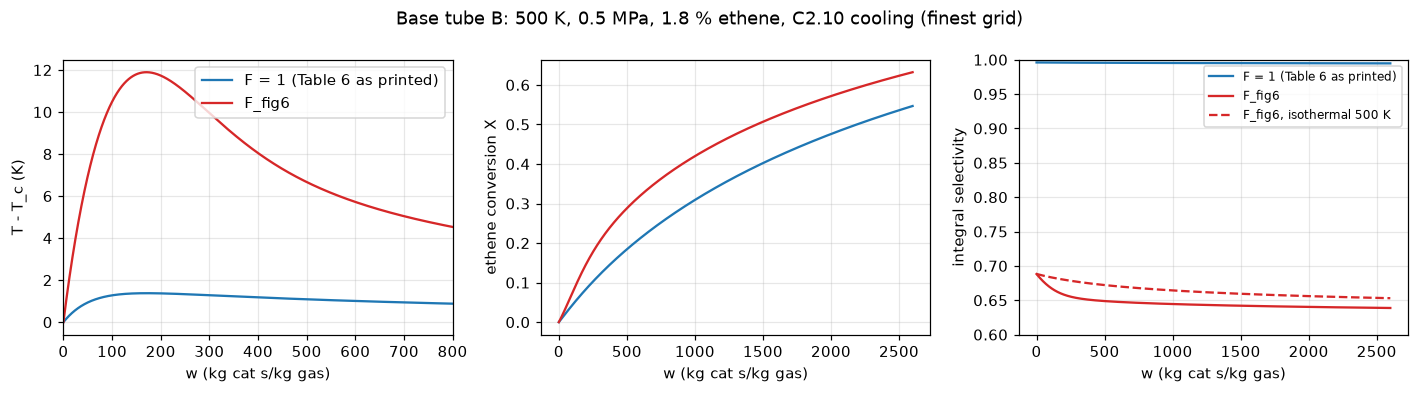

With Table 6 as printed the hot spot is 1.378 K above the coolant; with `F_fig6` it is 11.908 K, at w = 170.4 kg s/kg, about 3.2 cooling lengths c_p/h. Half the ethene is converted at w = 2190 (F = 1) and 1455 (`F_fig6`) with integral selectivities 0.9948 and 0.6423. Values are the Richardson extrapolation of the two finest of 4 grids (V3).

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for tag, col, lab in (("F1", "C0", "F = 1 (Table 6 as printed)"), ("F6", "C3", "F_fig6")):
    tb = BAUX[tag]["tube"]
    f = tb.faces
    X = 1 - f[:, 0] / tb.n_in[0]
    with np.errstate(invalid="ignore", divide="ignore"):
        sig = f[:, 3] / (tb.n_in[0] - f[:, 0])
    ax[0].plot(tb.w_f, f[:, 6] - tb.T_c, col, label=lab)
    ax[1].plot(tb.w_f, X, col, label=lab)
    ax[2].plot(tb.w_f[1:], sig[1:], col, label=lab)
ti = BAUX["iso"]["tube"]
fi = ti.faces
with np.errstate(invalid="ignore", divide="ignore"):
    ax[2].plot(ti.w_f[1:], (fi[:, 3] / (ti.n_in[0] - fi[:, 0]))[1:], "C3--",
               label="F_fig6, isothermal 500 K")
ax[0].set(xlabel="w (kg cat s/kg gas)", ylabel="T - T_c (K)", xlim=(0, 800))
ax[1].set(xlabel="w (kg cat s/kg gas)", ylabel="ethene conversion X")
ax[2].set(xlabel="w (kg cat s/kg gas)", ylabel="integral selectivity", ylim=(0.6, 1.0))
ax[0].legend(); ax[2].legend(fontsize=8)
fig.suptitle("Base tube B: 500 K, 0.5 MPa, 1.8 % ethene, C2.10 cooling (finest grid)")
fig.tight_layout(); plt.show()
say("With Table 6 as printed the hot spot is <<d1:.3f>> K above the coolant; with `F_fig6` "
    "it is <<d6:.3f>> K, at w = <<w6:.1f>> kg s/kg, about <<cl:.1f>> cooling lengths "
    "c_p/h. Half the ethene is converted at w = <<x1:.0f>> (F = 1) and <<x6:.0f>> "
    "(`F_fig6`) with integral selectivities <<s1:.4f>> and <<s6:.4f>>. Values are the "
    "Richardson extrapolation of the two finest of <<nl>> grids (V3).",
    d1=B["dTstar_B_F1"], d6=B["dTstar_B_F6"], w6=B["wstar_B_F6"],
    cl=B["wstar_B_F6"] * H_C210 / CP, x1=B["w_X50_B_F1"], x6=B["w_X50_B_F6"],
    s1=B["sigma_X50_B_F1"], s6=B["sigma_X50_B_F6"], nl=len(B_LEVELS))

In [15]:
show(pd.DataFrame({"component": T3.component, "lowest (bar)": T3.lowest_bar,
                   "highest (bar)": T3.highest_bar,
                   "B, F = 1 at X = 0.5": [f"{p:.4f}" for p in BAUX["P_X50"][0]],
                   "B, F_fig6 at X = 0.5": [f"{p:.4f}" for p in BAUX["P_X50"][1]]}), "d35t3")
say("At the X = 0.5 point of the two base tubes <<n>> of the <<N>> partial pressures lie "
    "inside the ranges of Table 3 (`C2.11`'s CSV); outside: <<out>>.",
    n=B["table3_inside_X50"], N=BAUX["inside"].size,
    out=", ".join(f"{T3.component.iloc[j]} ({'F = 1' if i == 0 else 'F_fig6'}, "
                  + ("below the lowest" if BAUX["P_X50"][i, j] < float(T3.lowest_bar.iloc[j])
                     else "above the highest") + " measured value)"
                  for i, j in zip(*np.nonzero(~BAUX["inside"]))))

component,lowest (bar),highest (bar),"B, F = 1 at X = 0.5","B, F_fig6 at X = 0.5"
ethene,0.006,0.18,0.0452,0.0451
oxygen,0.110,2.00,1.0099,0.9685
carbon dioxide,0.002,0.15,0.0005,0.0323
ethene oxide,0.002,0.12,0.0450,0.0290
water,0.001,0.14,0.0005,0.0323


At the X = 0.5 point of the two base tubes 8 of the 10 partial pressures lie inside the ranges of Table 3 (`C2.11`'s CSV); outside: carbon dioxide (F = 1, below the lowest measured value), water (F = 1, below the lowest measured value).

### R4: where the window becomes sensitive (the message)

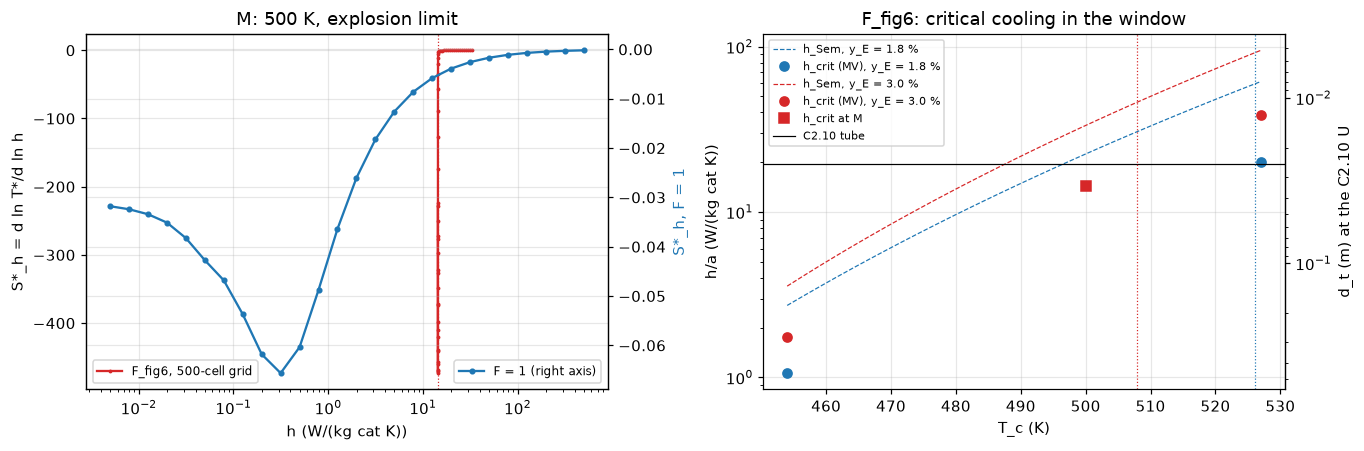

**With Table 6 as printed (F = 1) the window holds no sensitive point.** The largest |S*_h| over h from 0.005 to 500 W/(kg K) is 0.0634 at M and 0.0770 at the worst corner of the window (454 and 527 K, 1.8 and 3 %), against a peak of about -418 with `F_fig6` (extrapolated from 3 grids, 500 to 2000 cells, with the peak -473.40, -444.11, -430.48 and observed order 1.10, then a second Richardson step): the hot spot only follows the cooling. The F = 1 maximum at M sits at a hot spot of 558.9 K, past the highest kinetic temperature, 527 K: extrapolated kinetics. **With `F_fig6` the boundary lies inside the window.** At M the critical cooling is h_crit = 14.4493 W/(kg K), 0.4326 of the Semenov tangency; over the four corners the ratio lies between 0.327 and 0.493. The `C2.10` tube becomes critical at the explosion limit for coolant temperatures near 507.86 K, and at 1.8 % only within the top kelvin of the measured range (526.1 K). The hot spot at all 7 critical points computed (the four corners, M and the two `C2.10` points) lies above 527 K, the highest kinetic temperature: 734 K at M, 750 K for the `C2.10` tube at the explosion limit. At M the hot spot reaches 527 K only at h = 18.314, 1.2675 times the critical cooling. The boundary is therefore located only by extrapolated kinetics, which the paper warns against (S5).

**At M the criterion is intrinsic**: MV in y_E at h = h_crit(M) puts the critical ethene fraction at 0.030000, the explosion limit itself (shown at M only). **The normaliser matters little in h, more in T_c**: with the rise T* - T_c in place of T* the critical cooling at M moves by 3.8e-05 (relative), the critical coolant temperature of the `C2.10` tube at 1.8 % by -0.25 K, so that edge value is not robust. **The factor matters in proportion**: with `C2.11`'s Table 4 row 1 factor the critical cooling at M is 7.7964 W/(kg K), d ln h_crit/d ln F = 1.031. **Set against the spread of the factor itself**: `C2.11`'s factor varies by 0.148 percent between the Figure 6 curves, which moves h_crit by 0.153 percent through that slope. The h scan covers U, d_t, the voidage and the activity (E15), but not c_p.

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
sc = M_RES[0]["scan"]
ax[0].plot(sc["x"], sc["S"], "C3.-", ms=3, label="F_fig6, 500-cell grid")
ax[0].axvline(M["hcrit_MV_M_F6"], color="C3", lw=0.8, ls=":")
hs1, S1 = F1_SCAN
ax0b = ax[0].twinx()
ax0b.semilogx(hs1, S1, "C0o-", ms=3, label="F = 1 (right axis)")
ax0b.set_ylabel("S*_h, F = 1", color="C0")
ax[0].set(xscale="log", xlabel="h (W/(kg cat K))", ylabel="S*_h = d ln T*/d ln h",
          title="M: 500 K, explosion limit")
ax[0].legend(loc="lower left", fontsize=8); ax0b.legend(loc="lower right", fontsize=8)
Tg = np.linspace(min(T_KIN), T_HI, 30)
for y, col in ((Y_STD, "C0"), (Y_LEL, "C3")):
    ax[1].plot(Tg, [semenov(kin(F6), T, y)[0] for T in Tg], col + "--", lw=0.8,
               label=f"h_Sem, y_E = {100 * y:.1f} %")
    t_ = MAP_TAB[MAP_TAB.y_E == y]
    ax[1].plot(t_.T_c, t_.h_crit, col + "o", label=f"h_crit (MV), y_E = {100 * y:.1f} %")
ax[1].plot([T_STD], [M["hcrit_MV_M_F6"]], "C3s", label="h_crit at M")
ax[1].axhline(H_C210, color="k", lw=0.8, label="C2.10 tube")
for tag, col in (("03", "C3"), ("018", "C0")):
    ax[1].axvline(TC[f"Tc_crit_C210_{tag}_F6"], color=col, lw=0.8, ls=":")
ax[1].set(xlabel="T_c (K)", ylabel="h/a (W/(kg cat K))", yscale="log",
          title="F_fig6: critical cooling in the window")
sec = ax[1].secondary_yaxis("right", functions=(lambda h: 4 * GEO["U_C210_SI"] / (np.maximum(h, 1e-9) * GEO["rho_b_kgm3"]),
                                                lambda d: 4 * GEO["U_C210_SI"] / (np.maximum(d, 1e-9) * GEO["rho_b_kgm3"])))
sec.set_ylabel("d_t (m) at the C2.10 U")
ax[1].legend(fontsize=7, loc="upper left")
fig.tight_layout(); plt.show()
say("**With Table 6 as printed (F = 1) the window holds no sensitive point.** The largest "
    "|S*_h| over h from 0.005 to 500 W/(kg K) is <<s1:.4f>> at M and <<sw:.4f>> at the "
    "worst corner of the window (454 and 527 K, 1.8 and 3 %), against a peak of "
    "about <<sm:.0f>> with `F_fig6` (extrapolated from <<nsl>> grids, 500 to 2000 cells, with "
    "the peak <<sl>> and observed order <<so:.2f>>, then a second Richardson step): the "
    "hot spot only follows the cooling. The F = 1 maximum at M sits at a hot spot of "
    "<<tfm:.1f>> K, past the highest kinetic temperature, <<thi:.0f>> K: extrapolated "
    "kinetics. "
    "**With `F_fig6` the boundary lies inside the window.** At M the critical cooling is "
    "h_crit = <<hc:.4f>> W/(kg K), <<rr:.4f>> of the Semenov tangency; over the four "
    "corners the ratio lies between <<rmin:.3f>> and <<rmax:.3f>>. The `C2.10` tube "
    "becomes critical at the explosion limit for coolant temperatures near "
    "<<tc3:.2f>> K, and at 1.8 % only within the top kelvin of the measured range "
    "(<<tc18:.1f>> K). The hot spot at all <<nt>> critical points computed (the four "
    "corners, M and the two `C2.10` points) lies above <<thi:.0f>> K, the highest kinetic "
    "temperature: <<tsm:.0f>> K at M, <<ts3:.0f>> K for the `C2.10` tube at the explosion "
    "limit. At M the hot spot "
    "reaches <<thi:.0f>> K only at h = <<h5:.3f>>, <<h5r:.4f>> times the critical cooling. "
    "The boundary is therefore located only by extrapolated kinetics, which the paper "
    "warns against (S5).",
    s1=F1["max_abs_Sh_M_F1"], sw=F1["max_abs_Sh_window_F1"], sm=M["smin_MV_M_F6"],
    nsl=len(M["smin_levels"]), sl=", ".join(f"{v:.2f}" for v in M["smin_levels"]),
    so=float(np.ravel(M["smin_order"])[-1]), tfm=F1["Tstar_at_Sh_max_M_F1"],
    hc=M["hcrit_MV_M_F6"], rr=M["hcrit_over_hSem_M_F6"], rmin=MAP["map_ratio_min"],
    rmax=MAP["map_ratio_max"], tc3=TC["Tc_crit_C210_03_F6"], tc18=TC["Tc_crit_C210_018_F6"],
    thi=T_HI, tsm=M["Tstar_crit_M_F6"], ts3=TC["Tstar_crit_C210_03_F6"],
    nt=int(np.sum(top_count()[0] > T_HI)),
    h5=M["h527_M_F6"], h5r=M["h527_over_hcrit_M_F6"])
say("**At M the criterion is intrinsic**: MV in y_E at h = h_crit(M) puts the critical "
    "ethene fraction at <<yc:.6f>>, the explosion limit itself (shown at M only). **The normaliser matters "
    "little in h, more in T_c**: with the rise T* - T_c in place of T* the critical cooling "
    "at M moves by <<rh:.1e>> (relative), the critical coolant temperature of the `C2.10` "
    "tube at 1.8 % by <<rt:+.2f>> K, so that edge value is not robust. **The factor "
    "matters in proportion**: with `C2.11`'s Table 4 row 1 factor the critical cooling at "
    "M is <<hr:.4f>> W/(kg K), d ln h_crit/d ln F = <<dl:.3f>>. **Set against the spread of "
    "the factor itself**: `C2.11`'s factor varies by <<sp:.3f>> percent between the Figure 6 "
    "curves, which moves h_crit by <<mv:.3f>> percent through that slope. The h scan covers "
    "U, d_t, the voidage and the activity (E15), but not c_p.",
    yc=Y["ycrit_MV_at_hcrit_M_F6"], rh=RISE["hcrit_rise_shift_rel"],
    rt=RISE["Tc_crit_rise_shift_018_K"], hr=FR["hcrit_MV_M_Frow1"], dl=FR["dlnh_dlnF_M"],
    sp=SP["F_fig6_curve_spread_pct"], mv=SP["hcrit_move_F_spread_pct"])

### R5: what the hot spot costs in selectivity

The paper notes that selectivity falls with temperature (S7; the differential statement
is `C2.11`'s). In the tube the integral selectivity at half conversion differs from the
inlet value for two reasons, each measured as the difference of two solves that differ
by one ingredient: the products formed along the tube (isothermal tube against the inlet
value) and the hot spot (cooled tube against the isothermal tube).

In [17]:
say("At B with `F_fig6`: inlet <<s0:.4f>>, isothermal tube <<si:.4f>>, cooled tube "
    "<<sc:.4f>> at X = 0.5. The products cost <<cp:.4f>>, the <<dT:.1f>> K hot spot "
    "<<ch:.4f>>. Near the boundary (3 % ethene, h = 1.05 h_crit, hot spot <<dn:.1f>> K "
    "above the coolant, <<tn:.1f>> K, past the highest kinetic temperature, <<thi:.0f>> K: "
    "extrapolated kinetics) the hot spot costs <<cn:.4f>>, <<gr:.1f>> times as much. With "
    "Table 6 as printed the selectivity at X = 0.5 stays at <<s1:.4f>>.",
    s0=INL["sigma_in_B_F6"], si=B["sigma_X50_iso500_F6"], sc=B["sigma_X50_B_F6"],
    cp=B["sel_cost_products_B"], dT=B["dTstar_B_F6"], ch=B["sel_cost_hotspot_B"],
    dn=NC["dTstar_nc"], tn=T_STD + NC["dTstar_nc"], thi=T_HI, cn=NC["sel_cost_hotspot_nc"],
    gr=NC["sel_cost_hotspot_nc"] / B["sel_cost_hotspot_B"], s1=B["sigma_X50_B_F1"])

At B with `F_fig6`: inlet 0.6883, isothermal tube 0.6572, cooled tube 0.6423 at X = 0.5. The products cost 0.0311, the 11.9 K hot spot 0.0149. Near the boundary (3 % ethene, h = 1.05 h_crit, hot spot 51.3 K above the coolant, 551.3 K, past the highest kinetic temperature, 527 K: extrapolated kinetics) the hot spot costs 0.0663, 4.4 times as much. With Table 6 as printed the selectivity at X = 0.5 stays at 0.9948.

## Validation

**V1 to V6** each could fail; the numbers are this run's. The check values (above) are
the independent route (V7).

In [18]:
def v2_study(levels=(500, 1000, 2000, 4000, 8000, 16000), dT_in=0.0, h_root=None,
             actual=None):
    """V2: the frozen-composition limit at S. FV temperature at the face w_half against the
    quadrature; the long-tube outlet against the root T_s."""
    k = kin(F6)
    Tc = T_KIN[1]
    Ts, wh = Tc + INL["Ts_frozen_S_minus_Tc"], INL["w_half_frozen_S"]
    T_half = Tc + 0.5 * (Ts - Tc)
    vals = []
    for n in levels:
        n_run = (actual or {}).get(n, n)        # a break-row option: a level run unscaled
        tb = CooledTube(k, Y_STD, Tc, H_C210, CP, 4.0 * wh, n_run, mode="frozen")
        tb.u_in[6] += dT_in                       # inlet temperature (a break-row option)
        tb.g_const = (tb.g_inlet @ tb.u_in).reshape((-1, 1))
        tb.solve()
        vals.append(tb.faces[n_run // 4, 6])      # the face at w = w_half
    oo = observed_orders(lambda n: vals[levels.index(n)], list(levels), ratio=2.0)
    diffs = np.abs(np.diff(vals))
    if not np.all(np.finfo(float).eps * T_half / diffs < 1e-6):
        raise RuntimeError("V2: a successive difference within a million times round-off")
    hr = H_C210 if h_root is None else h_root
    g = lambda T: k.heat(T, inlet(Y_STD)) - hr * (T - Tc)
    root = find_roots(g, Tc, T_HI, n_scan=64, xtol=1e-12)["roots"][0]
    lt = CooledTube(k, Y_STD, Tc, H_C210, CP, 60.0 * CP / H_C210, 200, mode="frozen").solve()
    return {"V2_order_min": float(np.nanmin(oo["orders"])),
            "V2_order_max": float(np.nanmax(oo["orders"])),
            "V2_extrap_gap_K": abs(richardson(vals) - T_half),
            "V2_outlet_root_gap": abs(lt.outlet()[6] / root - 1.0)}, (levels, vals)


def v4_study(eps_jac=1e-8, rel_step=1e-3):
    """V4: dT*/dh from the Jacobian against a central difference of two solves at B."""
    k = kin(F6)
    tb = CooledTube(k, Y_STD, T_STD, H_C210, CP, 600.0, 2000, eps_jac=eps_jac)
    tb.trace("h", np.geomspace(4 * H_C210 + 1, H_C210, 4))
    _, Ts, dTs = tb.hot_spot(tb.sensitivity("h"))
    u0 = tb.u.copy()
    dh = rel_step * H_C210
    T_pm = []
    for sgn in (1.0, -1.0):
        tb.h = H_C210 + sgn * dh
        tb.solve(u0=u0, tol=1e-13)
        T_pm.append(tb.hot_spot()[1])
    fd = (T_pm[0] - T_pm[1]) / (2 * dh)
    return {"V4_sens_gap": abs(dTs / fd - 1.0)}


def v5_study(factor_on="r2"):
    """V5: the rate law at the Figure 6 point against C2.11's check values."""
    pn11 = load_data("borman-1995-printed-numbers.csv", page=C211, dtype=str).set_index("quantity")
    T = float(pn11.loc["fig6_T", "value"])
    P = np.array([float(pn11.loc[f"fig6_P_{j}", "value"]) for j in ("E", "O", "C", "EO", "W")])
    cv11 = load_data("check_values.csv", page=C211).set_index("name").value
    k = Kinetics(PAR, F=1.0, factor_on=factor_on)
    r1 = rate(PAR["r1"], T, P) * (k.F if factor_on == "r1" else 1.0)
    r2 = rate(PAR["r2"], T, P)
    from model import apparent_activation
    mine = {"r1_T": r1, "r2_T_printed": r2, "sigma_T_F1": r1 / (r1 + 0.5 * r2),
            "Eapp1_T_kJmol": apparent_activation(PAR["r1"], T, P) / 1e3,
            "Eapp2_T_kJmol": apparent_activation(PAR["r2"], T, P) / 1e3}
    if factor_on == "r1":                          # the factor F_fig6 put on r1
        mine["r1_T"] = r1 * F6
        mine["sigma_T_F1"] = F6 * r1 / (F6 * r1 + 0.5 * r2)
    dH11 = (pn11.loc["dH_epoxidation", "value"], pn11.loc["dH_combustion", "value"])
    return {"V5_c211_worst": max(abs(mine[n] / cv11[n] - 1.0) for n in mine)}, dH11


def v6_study(a=None, a_h=None):
    """V6: activity a on both rates equals a = 1 at h/a on a tube a times shorter in w
    (``a_h``, a break-row option, divides the cooling of the second tube instead of ``a``)."""
    a = F3_R2 if a is None else a
    a_h = a if a_h is None else a_h
    t1 = CooledTube(kin(F6, a=a), Y_STD, T_STD, H_C210, CP, 600.0, 2000)
    t1.trace("h", np.geomspace(4 * H_C210 + 1, H_C210, 4))
    t2 = CooledTube(kin(F6), Y_STD, T_STD, H_C210 / a_h, CP, 600.0 * a, 2000)
    t2.trace("h", np.geomspace(4 * H_C210 / a_h + 1, H_C210 / a_h, 4))
    return {"V6_activity_gap": abs((t1.hot_spot()[1] - T_STD) / (t2.hot_spot()[1] - T_STD) - 1)}


def repeat_study(override=None):
    """V5: every row this page's CSV repeats from `C2.11`'s printed-numbers CSV, compared as
    strings. ``override`` (a break-row option) replaces page values before the comparison."""
    pn11 = load_data("borman-1995-printed-numbers.csv", page=C211, dtype=str).set_index("quantity")
    mine = PN.value.to_dict()
    mine.update(override or {})
    same = {q: (q, q) for q in ("dH_epoxidation", "dH_combustion", "dH_EO_oxidation",
                                "conversion_limit")}
    same.update({"gas_particle_dT_max": ("gas_particle_dT_max", "dT_gas_particle_max"),
                 "standard_ethene": ("standard_ethene", "table4_feed_ethene"),
                 "last_series_activity": ("last_series_activity", "series3_activity_text")})
    pairs = [(mine[a], pn11.loc[b, "value"]) for a, b in same.values()]
    pairs.append((";".join(mine[f"T_kinetic_{i}"] for i in range(1, 5)),
                  pn11.loc["T_experiments", "value"]))
    pairs.append((f"{mine['P_total_low']}-{mine['P_total_high']}",
                  pn11.loc["P_total_range", "value"]))
    return {"repeated_rows_agree": sum(a == b for a, b in pairs)}, len(pairs)


V2, V2_LADDER = v2_study()
V4 = v4_study()
V5, DH11 = v5_study()
V6 = v6_study()
RP, N_RP = repeat_study()
say("**V1 balances.** Along every tube of the base study the C, H and O invariants change "
    "by at most <<v1:.1e>> (relative; bound 1e-12), and the adiabatic energy invariant by "
    "<<v1e:.1e>>: first-order upwind keeps every linear invariant cell by cell.",
    v1=B["V1_element_drift"], v1e=B["V1_energy_drift"])
say("**V2 frozen limit at S.** The FV temperature at w_half converges to the quadrature "
    "with observed orders <<o1:.4f>> to <<o2:.4f>> on <<nl>> grids (<<l0>> to <<l1>> cells, "
    "theory 1; every successive difference is more than a million times its round-off "
    "level eps T); the Richardson value differs from the quadrature by <<g:.1e>> K. The outlet of a long "
    "frozen tube equals the root T_s to <<og:.1e>> (relative): implicit Euler keeps the "
    "fixed point.", o1=V2["V2_order_min"], o2=V2["V2_order_max"], nl=len(V2_LADDER[0]),
    l0=V2_LADDER[0][0], l1=V2_LADDER[0][-1],
    g=V2["V2_extrap_gap_K"], og=V2["V2_outlet_root_gap"])
say("**V3 grid ladder at B.** T*, w at X = 0.5 and the integral selectivity there converge "
    "with orders <<o1:.4f>> to <<o2:.4f>> on <<nl>> grids (theory 1); the Richardson values "
    "are the ones checked against the solve_ivp route. The critical cooling at M on 500 "
    "and 1000 cells: <<h0:.5f>> and <<h1:.5f>>, extrapolated <<hc:.5f>>.",
    o1=B["V3_order_min"], o2=B["V3_order_max"], nl=len(B_LEVELS),
    h0=M_RES[0]["x"], h1=M_RES[1]["x"], hc=M["hcrit_MV_M_F6"])
say("**V4 sensitivity.** dT*/dh from the Newton Jacobian agrees with a central difference "
    "of two solves to <<g:.1e>> (relative).",
    g=V4["V4_sens_gap"])
say("**V5 `C2.11` reproduction.** At the Figure 6 point the page's rate law reproduces "
    "`C2.11`'s check values r1, r2, sigma and both apparent activation energies to "
    "<<w:.1e>>. The heats in `C2.11`'s CSV (<<a>>, <<b>> kJ/mol) are this page's.",
    w=V5["V5_c211_worst"], a=DH11[0], b=DH11[1])
say("Every row this page's CSV repeats from `C2.11`'s printed-numbers CSV (the heats, the "
    "kinetic temperatures, the pressure range, the conversion limit, the gas-particle "
    "temperature difference, the Table 4 ethene fraction and the last-series activity) is "
    "compared as a string: <<n>> of <<N>> repeated rows agree.",
    n=RP["repeated_rows_agree"], N=N_RP)
say("**V6 activity identity.** A tube at activity <<a:g>> (Table 6 f3 of r2) and the tube "
    "at activity 1, cooling h/a and length a w give the same hot spot to <<g:.1e>>.",
    a=F3_R2, g=V6["V6_activity_gap"])

**V1 balances.** Along every tube of the base study the C, H and O invariants change by at most 5.8e-15 (relative; bound 1e-12), and the adiabatic energy invariant by 2.7e-15: first-order upwind keeps every linear invariant cell by cell.

**V2 frozen limit at S.** The FV temperature at w_half converges to the quadrature with observed orders 0.9970 to 0.9996 on 6 grids (500 to 16000 cells, theory 1; every successive difference is more than a million times its round-off level eps T); the Richardson value differs from the quadrature by 2.0e-08 K. The outlet of a long frozen tube equals the root T_s to 1.1e-16 (relative): implicit Euler keeps the fixed point.

**V3 grid ladder at B.** T*, w at X = 0.5 and the integral selectivity there converge with orders 0.9831 to 1.0296 on 4 grids (theory 1); the Richardson values are the ones checked against the solve_ivp route. The critical cooling at M on 500 and 1000 cells: 14.42609 and 14.43770, extrapolated 14.44931.

**V4 sensitivity.** dT*/dh from the Newton Jacobian agrees with a central difference of two solves to 1.4e-06 (relative).

**V5 `C2.11` reproduction.** At the Figure 6 point the page's rate law reproduces `C2.11`'s check values r1, r2, sigma and both apparent activation energies to 1.8e-12. The heats in `C2.11`'s CSV (-105, -1323 kJ/mol) are this page's.

Every row this page's CSV repeats from `C2.11`'s printed-numbers CSV (the heats, the kinetic temperatures, the pressure range, the conversion limit, the gas-particle temperature difference, the Table 4 ethene fraction and the last-series activity) is compared as a string: 9 of 9 repeated rows agree.

**V6 activity identity.** A tube at activity 0.39 (Table 6 f3 of r2) and the tube at activity 1, cooling h/a and length a w give the same hot spot to 1.4e-14.

### Claims and the break table

Every number above is registered here. Each break row injects one defect through a
study's argument, reruns the studies that defect enters and records every claim those
studies return; a claim must be failed by at least one row.

In [19]:
ALL = {**GEO, **INL, **B, **M, **Y, **TC, **FR, **F1, **MAP, **NC, **RISE, **V2, **V4, **V5,
       **V6, **RP, **SP}
TIGHT = 1e-9          # closed forms, quadrature and root finds: deterministic to round-off
TUBE = 1e-6           # Richardson values of Newton solves (tol 1e-11 on scaled unknowns)
for name in ("V_ring_mm3", "m_particle_g", "rho_p_kgm3", "rho_p_min_kgm3", "rho_p_max_kgm3",
             "rho_hull_kgm3", "rho_b_kgm3", "U_C210_SI", "cp_C210_SI", "h_C210_W_per_kgK",
             "PO_min_LEL_bar", "dTad_epox_018", "dTad_comb_018", "dTad_epox_03",
             "dTad_comb_03", "q_in_B_F1", "q_in_B_F6", "sigma_in_B_F1", "sigma_in_B_F6",
             "Eq_in_B_kJmol_F1", "Eq_in_B_kJmol_F6", "hSem_B_F1", "hSem_B_F6",
             "Tt_minus_Tc_B_F1", "Tt_minus_Tc_B_F6", "hFK_B_F1", "hFK_B_F6", "hSem_M_F6",
             "hFK_over_hSem_B_F6", "hC210_over_hSem_B_F6", "hSem_S_F6",
             "Ts_frozen_S_minus_Tc", "w_half_frozen_S"):
    claims.value(name, ALL[name], rtol=TIGHT)
for name in ("dTstar_B_F1", "wstar_B_F1", "w_X50_B_F1", "sigma_X50_B_F1", "dT_X50_B_F1",
             "dTstar_B_F6", "wstar_B_F6", "w_X50_B_F6", "sigma_X50_B_F6", "dT_X50_B_F6",
             "sigma_X50_iso500_F6", "w_X50_iso500_F6", "sel_cost_products_B",
             "sel_cost_hotspot_B", "sel_cost_hotspot_nc", "dTstar_nc", "hcrit_MV_M_F6",
             "hcrit_over_hSem_M_F6", "h527_M_F6", "h527_over_hcrit_M_F6",
             "max_abs_Sh_M_F1", "max_abs_Sh_window_F1"):
    claims.value(name, ALL[name], rtol=TUBE)
# Critical points: the argmax of a flat peak is fixed only to about the square root of the
# minimiser's resolution, so values there move between BLAS kernels; each rtol is about ten
# times the spread measured over three kernels (the hot spot at a critical point is the
# least conditioned: dT*/dh is largest there).
for name, rtol in (("ycrit_MV_at_hcrit_M_F6", 1e-5), ("Tc_crit_C210_03_F6", 1e-5),
                   ("hcrit_MV_M_Frow1", 1e-5), ("dlnh_dlnF_M", 1e-5), ("map_ratio_max", 1e-5),
                   ("map_ratio_min", 1e-4), ("Tstar_crit_C210_03_F6", 5e-4)):
    claims.value(name, ALL[name], rtol=rtol, note="critical point; rtol from the kernel spread")
# The C2.10 tube at 1.8 %: its critical coolant temperature moves by about 2e-4 K between BLAS
# kernels (the S* peak in T_c is the flattest), so the page states what it shows, a critical
# point inside the top kelvin of the measured range, and the rise-normalised shift as a
# quarter kelvin; the check values hold the precise value to 1e-5 (above).
claims.bound("Tc_crit_C210_018_F6", TC["Tc_crit_C210_018_F6"], min=T_HI - 1.0, max=T_HI,
             basis="chosen", note="critical within the top kelvin of the kinetic range (p. 51)")
claims.bound("Tc_crit_rise_shift_018_K", RISE["Tc_crit_rise_shift_018_K"], min=-0.3, max=-0.2,
             basis="chosen", note="a quarter kelvin; fixed to about 1e-4 K by the flat peak")
claims.value("smin_MV_M_F6", M["smin_MV_M_F6"], rtol=2e-3,
             note="peak height of a near-cliff extremum, two Richardson steps on 500, 1000 and "
                  "2000 cells")
claims.value("F_fig6_curve_spread_pct", ALL["F_fig6_curve_spread_pct"], rtol=TIGHT,
             note="C2.11's claim F_fig6_curve_spread, in percent")
claims.value("hcrit_move_F_spread_pct", ALL["hcrit_move_F_spread_pct"], rtol=TUBE,
             note="spread of the factor times the logarithmic slope")
claims.value("Tstar_at_Sh_max_M_F1", ALL["Tstar_at_Sh_max_M_F1"], rtol=5e-4,
             note="hot spot at the F = 1 maximum of |S*_h| at M; rtol as for the critical points")
claims.value("Tstar_crit_M_F6", M["Tstar_crit_M_F6"], rtol=5e-4,
             note="critical point; rtol from the kernel spread")
claims.value("hcrit_rise_shift_rel", RISE["hcrit_rise_shift_rel"], rtol=1e-2,
             note="difference of two critical values each Richardson-extrapolated")
claims.exact("table3_inside_X50", B["table3_inside_X50"], margin=B["table3_margin"],
             min_margin=0.01, note="partial pressures at X = 0.5 inside Table 3, both F")
vals_top, thr = top_count()
claims.count("Tstar_crit_above_top", vals_top, thr, min_margin=0.01)
claims.exact("hess_identity", hess == int(PN.loc["dH_EO_oxidation", "value"]), structural=True,
             note="printed heats: -1323 + 105 = -1218, an identity of printed integers")
claims.bound("V1_element_drift", B["V1_element_drift"], max=1e-12, basis="identity")
claims.bound("V1_energy_drift", B["V1_energy_drift"], max=1e-12, basis="identity")
claims.bound("V2_order_min", V2["V2_order_min"], min=0.9, max=1.1, basis="theory")
claims.bound("V2_order_max", V2["V2_order_max"], min=0.9, max=1.1, basis="theory")
claims.bound("V2_extrap_gap_K", V2["V2_extrap_gap_K"], max=1e-6, basis="theory",
             note="second-order remainder after one Richardson step on the 16000-cell pair")
claims.bound("V2_outlet_root_gap", V2["V2_outlet_root_gap"], max=1e-12, basis="identity")
claims.bound("V3_order_min", B["V3_order_min"], min=0.9, max=1.1, basis="theory")
claims.bound("V3_order_max", B["V3_order_max"], min=0.9, max=1.1, basis="theory")
claims.bound("V4_sens_gap", V4["V4_sens_gap"], max=1e-5, basis="tolerance",
             note="central difference, step 1e-3 h, plus NumJac eps_jac 1e-8")
claims.bound("V5_c211_worst", V5["V5_c211_worst"], max=1e-11, basis="tolerance",
             note="the rtol of C2.11's check rows")
claims.exact("repeated_rows_agree", RP["repeated_rows_agree"],
             note="rows repeated from C2.11's printed-numbers CSV, string equality")
claims.bound("V6_activity_gap", V6["V6_activity_gap"], max=1e-10, basis="identity",
             note="replacing w by a w maps (a, h) onto (1, h/a) exactly (E15)")

H_U_RAW = geometry(u_unit=1.0)["h_C210_W_per_kgK"]
DH2_MISREAD = 1232e3            # J/mol: the printed 1323 with two digits transposed
ROWS = [
    ("ring volume as the hull (hole ignored)", [(geometry, dict(hull_for_ring=True))]),
    ("U 82.7 kcal/(m2 h K) read as W/(m2 K)",
     [(geometry, dict(u_unit=1.0)), (tc_study, dict(h=H_U_RAW))]),
    ("batch of 69 particles read as 96", [(geometry, dict(n_part=96.0))]),
    ("c_p 0.25 kcal/(kg K) read as kJ/(kg K)", [(geometry, dict(cp_unit=1000.0))]),
    ("O2 per combustion 2.5 (ethene oxide's), invariants as printed",
     [(geometry, dict(o2_per_burnt=2.5)), (b_study, dict(o2_per_burnt=2.5))]),
    ("combustion heat 1323 kJ/mol read as 1232",
     [(inlet_study, dict(dH2=DH2_MISREAD)), (b_study, dict(dH2=DH2_MISREAD)),
      (m_study, dict(dH2=DH2_MISREAD, s_levels=None)), (map_study, dict(dH2=DH2_MISREAD)),
      (f1_study, dict(dH2=DH2_MISREAD)), (nc_study, dict(dH2=DH2_MISREAD)),
      (rise_study, dict(dH2=DH2_MISREAD))]),
    ("product inhibition off (K_C = K_EO = K_W = 0)", [(m_study, dict(inhibition=False, s_levels=None))]),
    ("y-criterion evaluated at 0.9 h_crit", [(y_study, dict(h_factor=0.9))]),
    ("Table 4 row 2 factor in place of row 1", [(frow1_study, dict(F=C211_CLAIMS["F_row2"]))]),
    ("isothermal reference at T_c + 10 K",
     [(b_study, dict(iso_dT=10.0)), (nc_study, dict(iso_dT=10.0))]),
    ("Table 3 ranges read in units of 10 mbar", [(table3_count, dict(P=BAUX["P_X50"],
                                                                     scale=0.01))]),
    ("grid ladder with one level unscaled (3000 cells run for 4000)",
     [(b_study, dict(actual={4000: 3000})), (v2_study, dict(actual={4000: 3000}))]),
    ("selectivity r1/(r1 + r2), without the factor 1/2", [(inlet_study, dict(sel_nu=1.0))]),
    ("feed 1.8 % ethene read as 1.6 %", [(b_study, dict(y=0.016))]),
    ("FV inlet temperature T_c + 1e-3 K", [(v2_study, dict(dT_in=1e-3))]),
    ("frozen root with h 1 % high", [(v2_study, dict(h_root=1.01 * H_C210)),
                                     (inlet_study, dict(h_frozen=1.01 * H_C210))]),
    ("NumJac eps_jac 1e-3 in the sensitivity", [(v4_study, dict(eps_jac=1e-3))]),
    ("F_fig6 applied to r1 at the Figure 6 point", [(v5_study, dict(factor_on="r1"))]),
    ("one repeated Table 4 ethene fraction misread (1.6 for 1.8)",
     [(repeat_study, dict(override={"standard_ethene": "1.6"}))]),
    ("spread of F_fig6 read as a percentage instead of a fraction",
     [(spread_study, dict(spread=100.0 * C211_CLAIMS["F_fig6_curve_spread"]))]),
    ("activity check with the second tube at cooling h instead of h/a",
     [(v6_study, dict(a_h=1.0))]),
    ("top kinetic temperature 527 K misread as 827 K", [(top_count, dict(T_top=827.0))]),
]
claims.define_rows([label for label, _ in ROWS])
BREAK, CRASH = [], []
for label, runs in ROWS:
    got = {}
    for fn, kw in runs:
        try:
            with np.errstate(all="ignore"):
                r = fn(**kw)
        except (RuntimeError, ValueError, FloatingPointError) as e:
            CRASH.append(f"{label}: {fn.__name__}: {type(e).__name__}: {str(e)[:120]}")
            continue
        r = r[0] if isinstance(r, tuple) else r
        if fn is top_count:
            got["Tstar_crit_above_top"] = int(np.sum(r > kw["T_top"]))
        else:
            got.update(r)
    for name, x in got.items():
        if name in claims.metrics and not claims.metrics[name].get("structural"):
            if isinstance(x, (float, np.floating)) and not np.isfinite(x):
                continue
            BREAK.append((label, name, claims.breaks(label, name, x)))
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
bt = pd.DataFrame([(r_, sum(cs), len(cs)) for r_, cs in by_row.items()],
                  columns=["injected defect", "claims failed", "claims recorded"])
show(bt, "d35bt")
caught = {m_ for r_, m_, c_ in BREAK if c_}
open_ = sorted(k_ for k_ in claims.metrics if k_ not in caught
               and not claims.metrics[k_].get("structural"))
print(f"rows that crashed: {'; '.join(CRASH) or 'none'}")
print(f"{len(ROWS)} rows; {len(caught)} of {len(claims.metrics)} claims are failed by at least "
      f"one row; open: {', '.join(open_) or 'none'}")

injected defect,claims failed,claims recorded
ring volume as the hull (hole ignored),4,15
U 82.7 kcal/(m2 h K) read as W/(m2 K),5,18
batch of 69 particles read as 96,7,15
c_p 0.25 kcal/(kg K) read as kJ/(kg K),5,15
"O2 per combustion 2.5 (ethene oxide's), invariants as printed",15,34
combustion heat 1323 kJ/mol read as 1232,42,52
product inhibition off (K_C = K_EO = K_W = 0),6,6
y-criterion evaluated at 0.9 h_crit,1,1
Table 4 row 2 factor in place of row 1,2,2
isothermal reference at T_c + 10 K,5,21


rows that crashed: none
22 rows; 84 of 85 claims are failed by at least one row; open: none


### The finding

In [20]:
say("With Table 6 as printed the paper's own window offers no parametrically sensitive "
    "tube: the hot spot follows the cooling, and its largest normalised sensitivity over "
    "the window (<<sw:.4f>>) is far below the peak the combustion factor gives (about "
    "<<sm:.0f>>). With the combustion factor that reproduces the authors' Figure 6 the "
    "runaway boundary runs through the window, and every critical point lies above the "
    "highest temperature at which the kinetics were measured, so it is located only by "
    "extrapolation (S5). This supports `C2.11`'s finding M1 from the reactor side, since "
    "under the printed table the window chosen to study heat effects (S1) holds no "
    "sensitive tube; it does not prove it, and it says nothing about why the printed "
    "constant differs. The flammability of the feed at the explosion limit is not "
    "modelled.",
    sw=F1["max_abs_Sh_window_F1"], sm=M["smin_MV_M_F6"])

With Table 6 as printed the paper's own window offers no parametrically sensitive tube: the hot spot follows the cooling, and its largest normalised sensitivity over the window (0.0770) is far below the peak the combustion factor gives (about -418). With the combustion factor that reproduces the authors' Figure 6 the runaway boundary runs through the window, and every critical point lies above the highest temperature at which the kinetics were measured, so it is located only by extrapolation (S5). This supports `C2.11`'s finding M1 from the reactor side, since under the printed table the window chosen to study heat effects (S1) holds no sensitive tube; it does not prove it, and it says nothing about why the printed constant differs. The flammability of the feed at the explosion limit is not modelled.

## What pymrm adds

The paper prints kinetics, no tube; everything about the tube is this page's. pymrm
contributes the steady tube as one sparse Newton system on the whole axis
(`construct_convflux_upwind`, `construct_div`, `NumJac`, `newton` with per-field scale
and bounds), `continuation` to follow it through the sensitive region from the stable
side, the converged Jacobian that gives $dT^*/d\phi$ for the criterion by one sparse
solve at every scan point, `find_roots` for the tangency, the frozen root, the half
conversion point and the cooling at which the hot spot reaches the top kinetic
temperature, and `observed_orders` for the grid ladders. The same answers come from a
scipy `solve_ivp` integration with forward sensitivities (the check values); pymrm's
part is the steady formulation and its Jacobian, not an answer a march could not give.

## Reuse

- Another catalyst or reaction pair: replace `Kinetics.rates` and `sources`; the tube,
  the sensitivity and the critical-point march (`scan_sensitivity`, `refine_extremum`,
  `critical_point`) take any pointwise source.
- Another tube: `h = 4U/(d_t rho_b)` is the only tube input; the maps are in $h/a$, so a
  different activity, diameter or wall coefficient is a move along the axis (E15).
- A finer criterion study: `CooledTube.mv` returns both normalisations; `sensitivity`
  takes `h`, `T_c` or `y_E`.
- Related pages: `C2.11` (the kinetics and the factor), `C2.10` (the borrowed tube, 1-D
  against 2-D), `D2.2` (Van Welsenaere-Froment criteria on one reaction), `D2.1`
  (Barkelew), `D1.1` (film and particle rungs), `D2.3` (the generalized criterion).

In [21]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for D3.5:
  V_ring_mm3               = 415.8            value  rtol 1e-09
  m_particle_g             = 0.68116          value  rtol 1e-09
  rho_p_kgm3               = 1638.2           value  rtol 1e-09
  rho_p_min_kgm3           = 1445.4           value  rtol 1e-09
  rho_p_max_kgm3           = 1876.9           value  rtol 1e-09
  rho_hull_kgm3            = 1429.2           value  rtol 1e-09
  rho_b_kgm3               = 786.08           value  rtol 1e-09
  U_C210_SI                = 96.116           value  rtol 1e-09
  cp_C210_SI               = 1046             value  rtol 1e-09
  h_C210_W_per_kgK         = 19.564           value  rtol 1e-09
  PO_min_LEL_bar           = 0.56588          value  rtol 1e-09
  dTad_epox_018            = 62.418           value  rtol 1e-09
  dTad_comb_018            = 786.46           value  rtol 1e-09
  dTad_epox_03             = 104.07           value  rtol 1e-09
  dTad_comb_03             = 1311.3           value  rtol 1e-09
  q_in_B_F1            